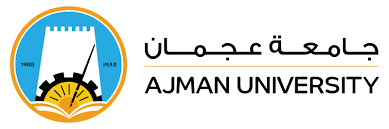


# Project Title: Studying Diabetes Dataset
College of Engineering and Information Technology (CEIT)

Department of Information Technology (IT)

1st Semester 2025-2026

DAT203 : Probability Theory and its Applications

---


**Supervised By: Dr. Huseyin Kusetogullari**



Team members


1.   Hayatt AlAbed 202410038
2.   Asmaa Alsaloum 202410458

**we loaded all the Python libraries so they can be used throughout the project**


In [18]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from scipy.stats import norm
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


**Importing the data**


In [19]:
df = pd.read_excel("/content/Data.xlsx")
df

,Gender,Height_cm,Weight_kg,Cholesterol_mg_dL,Diabetes
0,M,161.220174,67.928450,206.674781,0
1,F,161.731196,77.664126,183.204176,0
2,M,167.735211,69.237118,177.087169,0
3,M,173.673655,52.588865,250.254190,0
4,M,179.135846,70.906916,145.829378,0
...,...,...,...,...,...
3995,F,172.689781,91.190359,256.343511,1
3996,F,163.080431,70.586900,293.704972,1
3997,F,181.280569,49.197702,246.745540,1
3998,F,158.272355,85.411336,247.662215,1


In [20]:
df.rename(columns={'Gender': 'Gender', 'Weight_kg': 'Weight', 'Height_cm': 'Height', 'Cholesterol_mg_dL': 'Cholesterol', 'Diabetes': 'Diabetes'}, inplace=True)

print(df.head())

  Gender      Height     Weight  Cholesterol  Diabetes
0      M  161.220174  67.928450   206.674781         0
1      F  161.731196  77.664126   183.204176         0
2      M  167.735211  69.237118   177.087169         0
3      M  173.673655  52.588865   250.254190         0
4      M  179.135846  70.906916   145.829378         0


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Gender       4000 non-null   object 
 1   Height       4000 non-null   float64
 2   Weight       4000 non-null   float64
 3   Cholesterol  4000 non-null   float64
 4   Diabetes     4000 non-null   int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 156.4+ KB


In [22]:
df.describe()

,Height,Weight,Cholesterol,Diabetes
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,168.853053,74.993637,205.017156,0.500000
std,10.014605,14.701123,35.869191,0.500063
min,140.000000,40.000000,100.000000,0.000000
25%,162.097577,64.858194,180.256830,0.000000
50%,168.875944,74.371127,203.428785,0.500000
75%,175.518806,84.696201,228.624803,1.000000
max,209.262377,130.660744,340.011867,1.000000


In [23]:
print('number of duplicated values in each column:')
df.duplicated().sum()

number of duplicated values in each column:


np.int64(0)

In [24]:
print('number of missing values in each column:')
df.isnull().sum()

number of missing values in each column:


,0
Gender,0
Height,0
Weight,0
Cholesterol,0
Diabetes,0


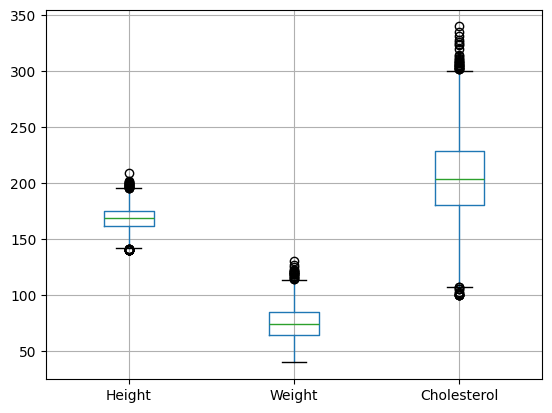

In [25]:
df[['Height', 'Weight','Cholesterol']].boxplot()
plt.show()

In [26]:
# Handling outliers
for col in df.columns:
    if df[col].dtype == 'float64' or df[col].dtype == 'float32':
        # Calculate IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR


        df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)


        remaining_outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

        print(f"Column '{col}' clipped: lower={lower_limit}, upper={upper_limit}")
        print(f"{col} remaining outliers: {len(remaining_outliers)}")


Column 'Height' clipped: lower=141.96573462101296, upper=195.65064857704132
Height remaining outliers: 0
Column 'Weight' clipped: lower=35.10118304655313, upper=114.45321099628595
Weight remaining outliers: 0
Column 'Cholesterol' clipped: lower=107.70487191316768, upper=301.17676117753984
Cholesterol remaining outliers: 0


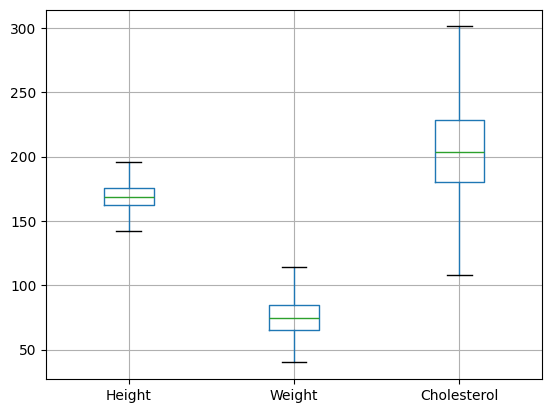

In [27]:
df[[ 'Height', 'Weight','Cholesterol']].boxplot()
plt.show()

In [28]:
# Lable Encoding
encoder = LabelEncoder()
df['Gender'] = encoder.fit_transform(df['Gender'])
df

,Gender,Height,Weight,Cholesterol,Diabetes
0,1,161.220174,67.928450,206.674781,0
1,0,161.731196,77.664126,183.204176,0
2,1,167.735211,69.237118,177.087169,0
3,1,173.673655,52.588865,250.254190,0
4,1,179.135846,70.906916,145.829378,0
...,...,...,...,...,...
3995,0,172.689781,91.190359,256.343511,1
3996,0,163.080431,70.586900,293.704972,1
3997,0,181.280569,49.197702,246.745540,1
3998,0,158.272355,85.411336,247.662215,1


In [29]:
# This ensures (0 = female, 1 = Male)
gender_mapping = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))

print("Gender mapping:", gender_mapping)


Gender mapping: {'F': np.int64(0), 'M': np.int64(1)}


**Train/Test Split**



In [30]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['Diabetes'])
print("Training set size:", len(train_df))
print("Test set size:", len(test_df))

Training set size: 3200
Test set size: 800


**Univariate Analysis (Histograms, PMF, and CDF)**

In [31]:
cols = ['Height','Weight','Cholesterol']

Height: Sum of probabilities = 1.0000
Weight: Sum of probabilities = 1.0000
Cholesterol: Sum of probabilities = 1.0000


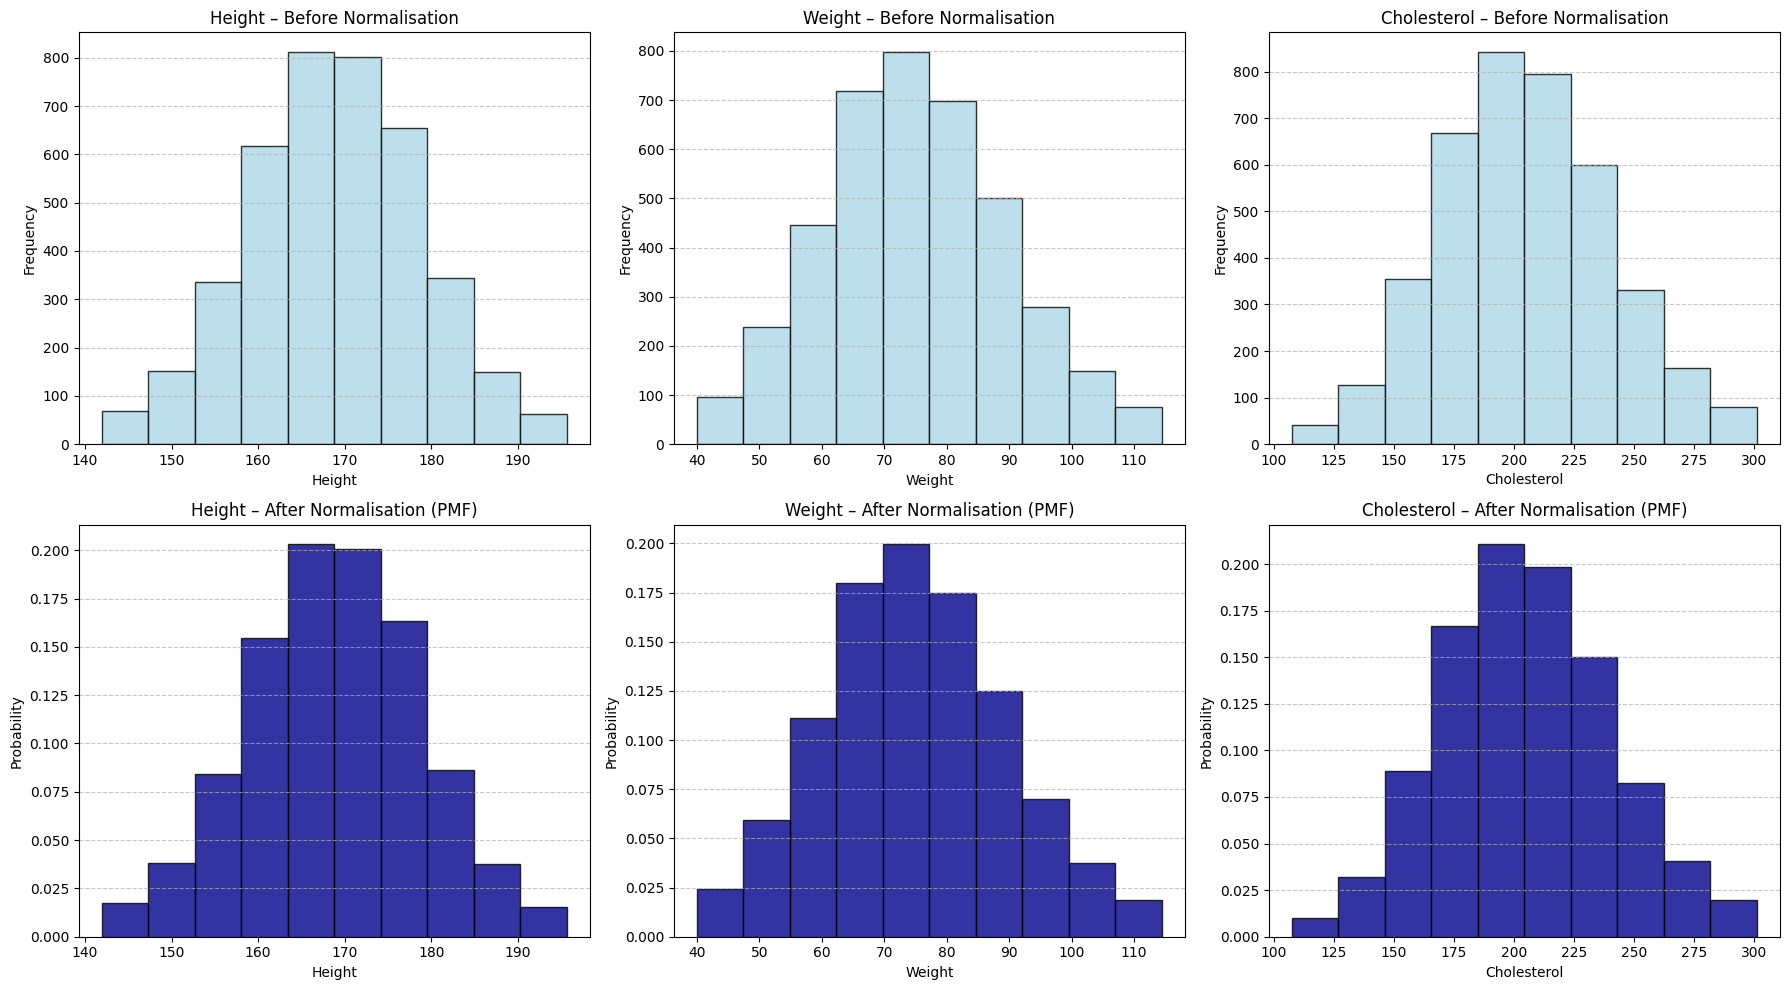

In [32]:
bins = 10

fig, axes = plt.subplots(2, len(cols), figsize=(18, 10))

for i, col in enumerate(cols):
    data = df[col].values

    # BEFORE NORMALISATION
    counts, bin_edges = np.histogram(data, bins=bins)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

    ax1 = axes[0, i]
    ax1.bar(bin_centers, counts,
            width=(bin_edges[1] - bin_edges[0]),
            color='lightblue', edgecolor='black', alpha=0.8)
    ax1.set_title(f'{col} – Before Normalisation', fontsize=12)
    ax1.set_xlabel(col)
    ax1.set_ylabel('Frequency')
    ax1.grid(axis='y', linestyle='--', alpha=0.7)

    # AFTER NORMALISATION
    probabilities = counts / counts.sum()

    ax2 = axes[1, i]
    ax2.bar(bin_centers, probabilities,
            width=(bin_edges[1] - bin_edges[0]),
            color='darkblue', edgecolor='black', alpha=0.8)
    ax2.set_title(f'{col} – After Normalisation (PMF)', fontsize=12)
    ax2.set_xlabel(col)
    ax2.set_ylabel('Probability')
    ax2.grid(axis='y', linestyle='--', alpha=0.7)

    print(f"{col}: Sum of probabilities = {probabilities.sum():.4f}")

plt.tight_layout()
plt.show()

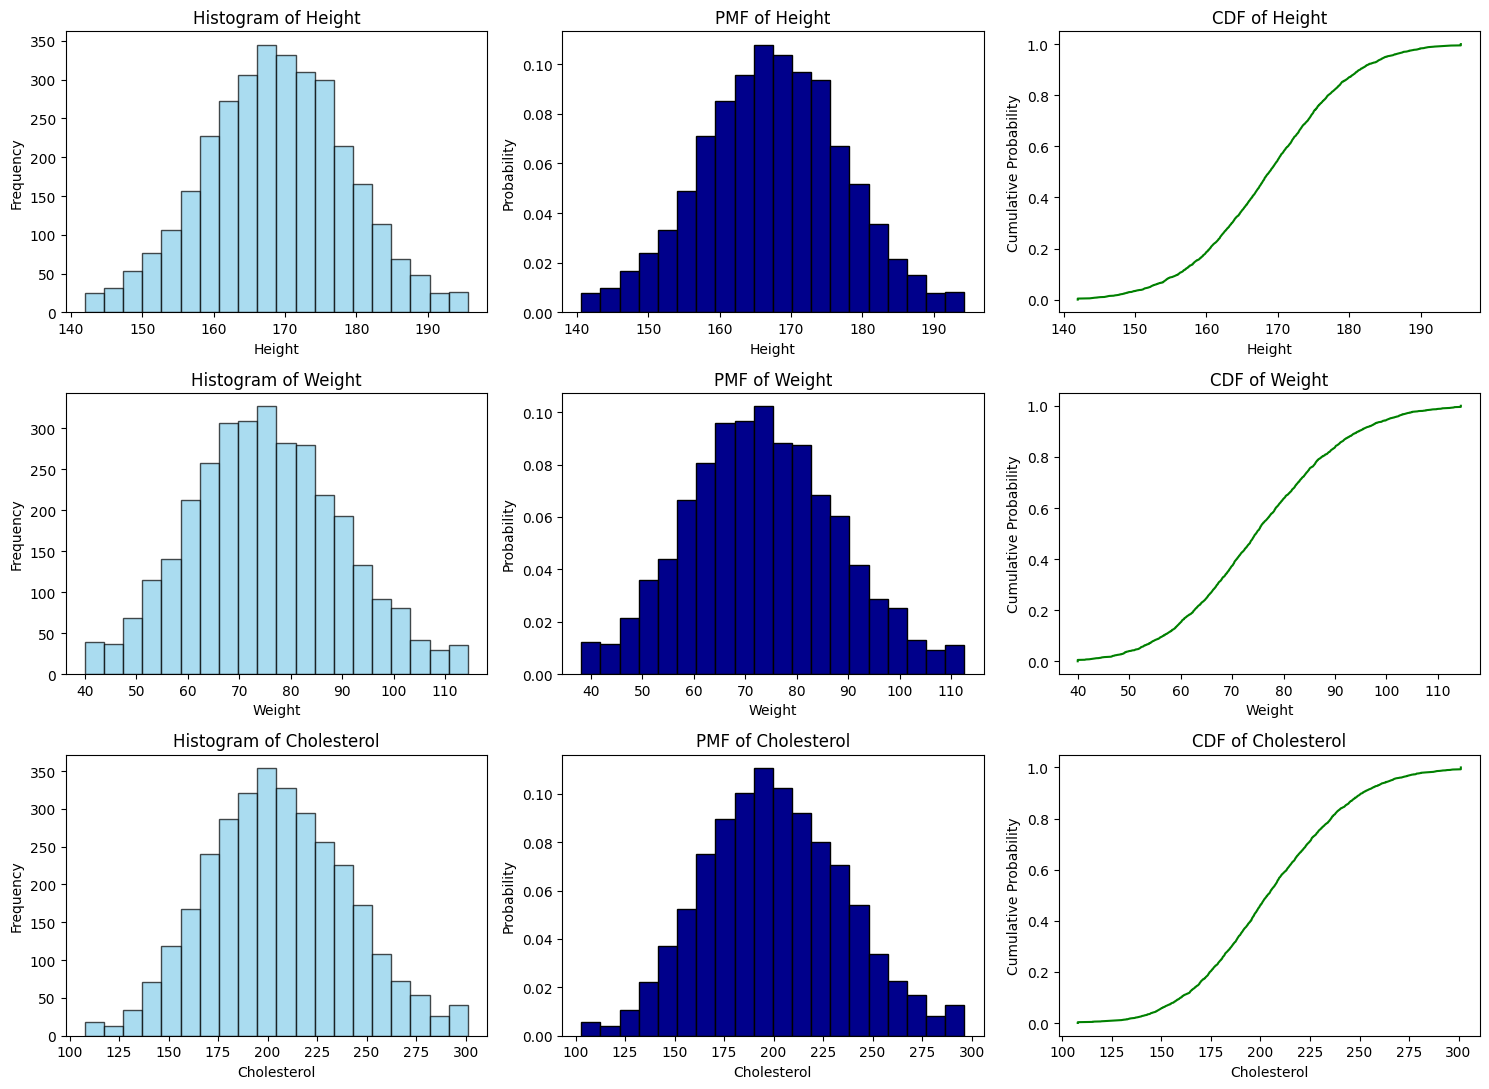

In [33]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['Diabetes'])
import matplotlib.pyplot as plt
import numpy as np

plot_idx = 0
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for col in cols:
    # --- Histogram ---
    axes[plot_idx].hist(train_df[col].dropna(), bins=20, density=False, alpha=0.7,
                        color='skyblue', edgecolor='black')
    axes[plot_idx].set_title(f'Histogram of {col}')
    axes[plot_idx].set_xlabel(col)
    axes[plot_idx].set_ylabel('Frequency')
    plot_idx += 1

    # --- PMF ---
    data = train_df[col].dropna()
    counts, bins = np.histogram(data, bins=20)
    pmf = counts / counts.sum()
    axes[plot_idx].bar(bins[:-1], pmf, width=(bins[1] - bins[0]),
                       color='darkblue', edgecolor='black')
    axes[plot_idx].set_title(f'PMF of {col}')
    axes[plot_idx].set_xlabel(col)
    axes[plot_idx].set_ylabel('Probability')
    plot_idx += 1

    # --- CDF ---
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[plot_idx].plot(x, y, color='green')
    axes[plot_idx].set_title(f'CDF of {col}')
    axes[plot_idx].set_xlabel(col)
    axes[plot_idx].set_ylabel('Cumulative Probability')
    plot_idx += 1


plt.tight_layout()
plt.show()

** Effect of bin width (explicit demonstration)**

In [34]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['Diabetes'])
print("Training set size:", len(train_df))
print("Test set size:", len(test_df))

Training set size: 3200
Test set size: 800



Effect of bin width for Weight:

Effect of bin width for Height:

Effect of bin width for Cholesterol:


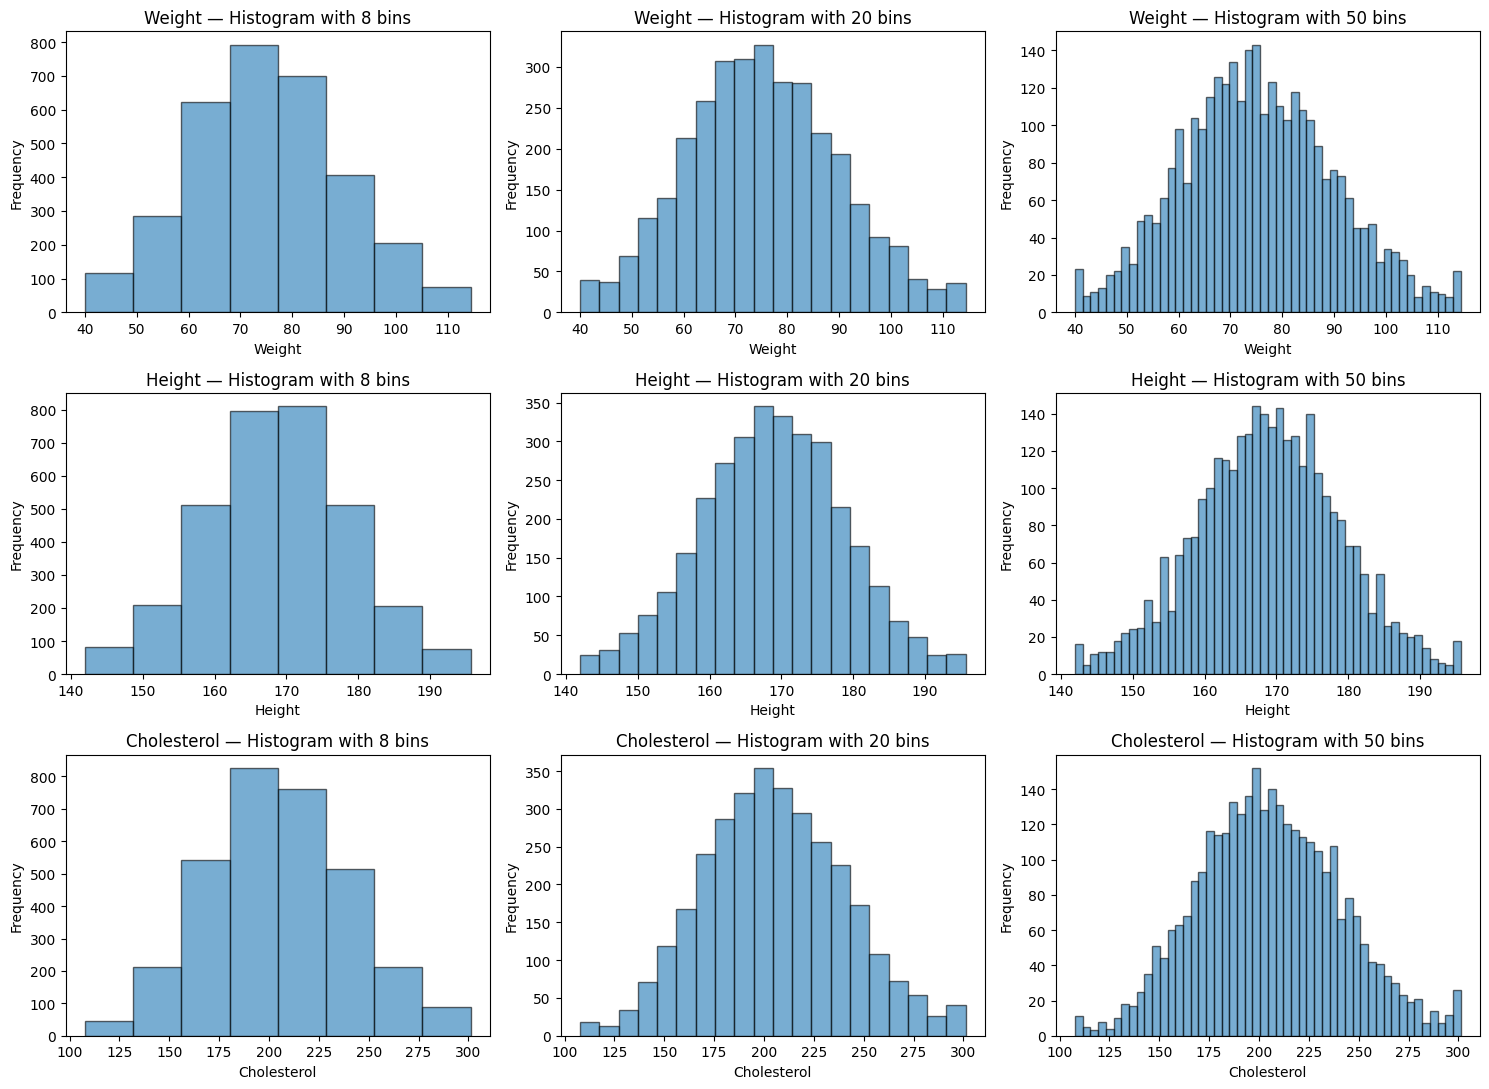

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

plot_idx = 0


for col in ['Weight', 'Height', 'Cholesterol']:
    print(f"\nEffect of bin width for {col}:")
    for bins in [8, 20, 50]:
        axes[plot_idx].hist(train_df[col], bins=bins, edgecolor='black', alpha=0.6)
        axes[plot_idx].set_title(f'{col} — Histogram with {bins} bins')
        axes[plot_idx].set_xlabel(col)
        axes[plot_idx].set_ylabel('Frequency')
        plot_idx += 1

for i in range(plot_idx, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

**Statistical Moments (Mean, Variance, Skewness, Kurtosis)**

In [36]:
# Determine mean, variance, skewness, kurtosis, for the variables: Weight, Heught, Cholesterol
cols = ['Weight', 'Height','Cholesterol']
for col in cols:
    mean = df[col].mean()
    var = df[col].var()
    skew = df[col].skew()
    kurt = df[col].kurtosis()

    print(f"Statistics for {col}:")
    print(f"  Mean: {mean:.3f}")
    print(f"  Variance: {var:.3f}")
    print(f"  Skewness: {skew:.3f}")
    print(f"  Kurtosis: {kurt:.3f}")
    print("-" * 40)

Statistics for Weight:
  Mean: 74.965
  Variance: 213.648
  Skewness: 0.166
  Kurtosis: -0.226
----------------------------------------
Statistics for Height:
  Mean: 168.843
  Variance: 98.945
  Skewness: -0.025
  Kurtosis: -0.131
----------------------------------------
Statistics for Cholesterol:
  Mean: 204.947
  Variance: 1265.315
  Skewness: 0.159
  Kurtosis: -0.112
----------------------------------------


**Gaussian (Normal) Approximation**

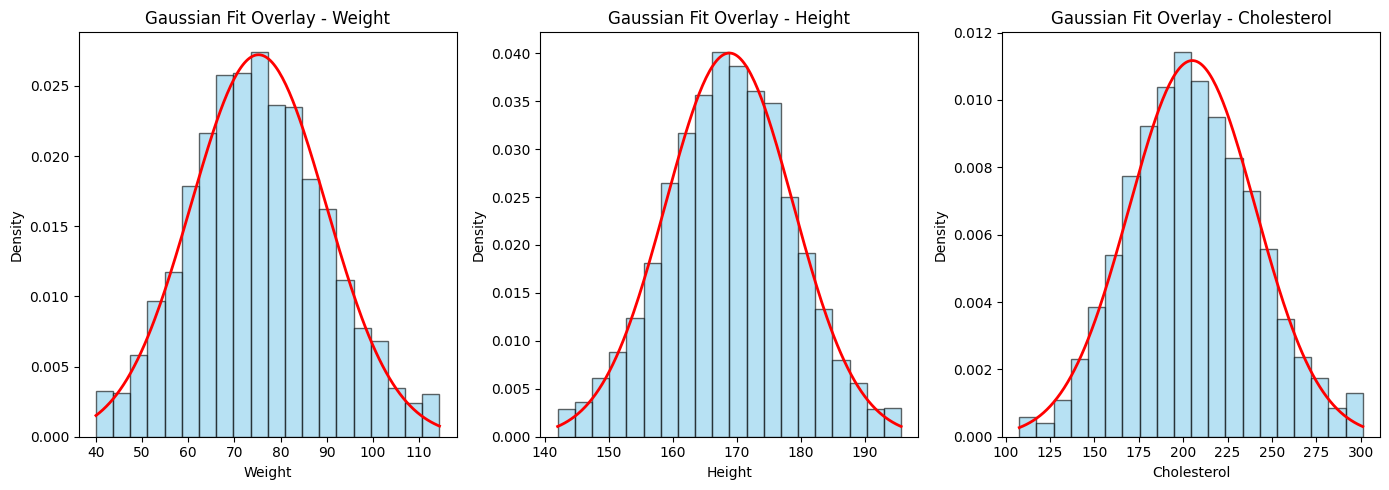

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for idx, col in enumerate(['Weight', 'Height','Cholesterol']):
    data = train_df[col].dropna()
    mu, sigma = data.mean(), data.std(ddof=1)
    x = np.linspace(data.min(), data.max(), 200)


    axes[idx].hist(data, bins=20, density=True, alpha=0.6, color='skyblue', edgecolor='black')
    axes[idx].plot(x, stats.norm.pdf(x, mu, sigma), color='red', linewidth=2)
    axes[idx].set_title(f'Gaussian Fit Overlay - {col}')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Density')

plt.tight_layout()
plt.show()


**Covariance and Correlation**


Covariance(Weight,Height): -9.113
Correlation(Weight,Height): -0.062

Covariance(Weight,Cholesterol): 83.878
Correlation(Weight,Cholesterol): 0.160

Covariance(Height,Cholesterol): -12.162
Correlation(Height,Cholesterol): -0.034


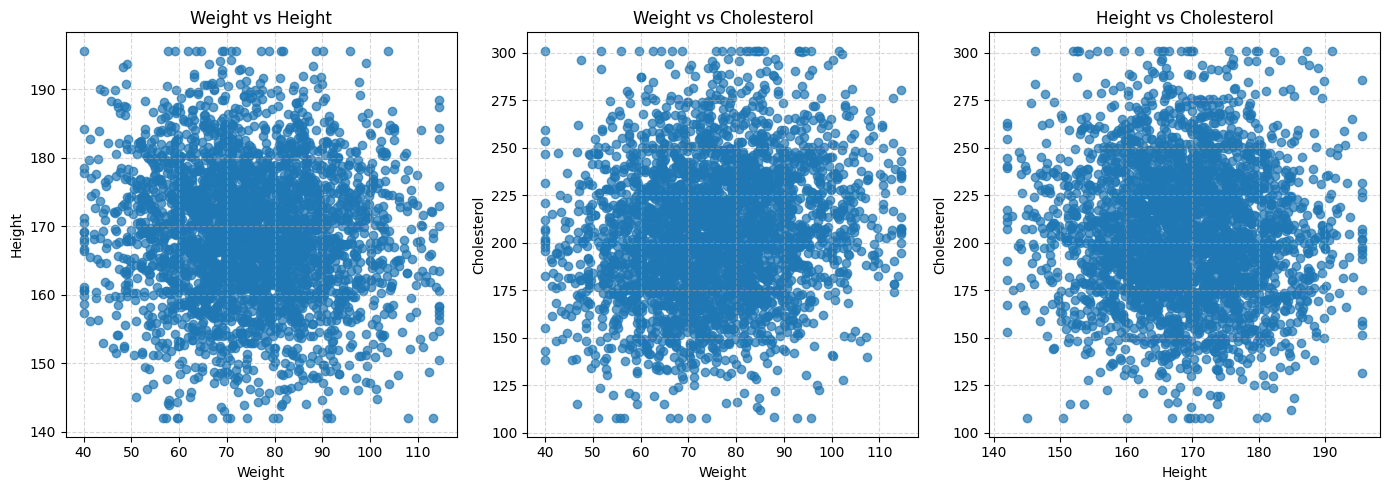

In [38]:
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np


pairs = [('Weight', 'Height'), ('Weight', 'Cholesterol'), ('Height', 'Cholesterol')]


fig, axes = plt.subplots(1, 3, figsize=(14, 5))


for idx, (x_col, y_col) in enumerate(pairs):

    cov = np.cov(train_df[x_col], train_df[y_col], ddof=1)[0, 1]
    r, _ = stats.pearsonr(train_df[x_col], train_df[y_col])

    print(f"\nCovariance({x_col},{y_col}): {cov:.3f}")
    print(f"Correlation({x_col},{y_col}): {r:.3f}")


    axes[idx].scatter(train_df[x_col], train_df[y_col], alpha=0.7)
    axes[idx].set_title(f'{x_col} vs {y_col}')
    axes[idx].set_xlabel(x_col)
    axes[idx].set_ylabel(y_col)
    axes[idx].grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

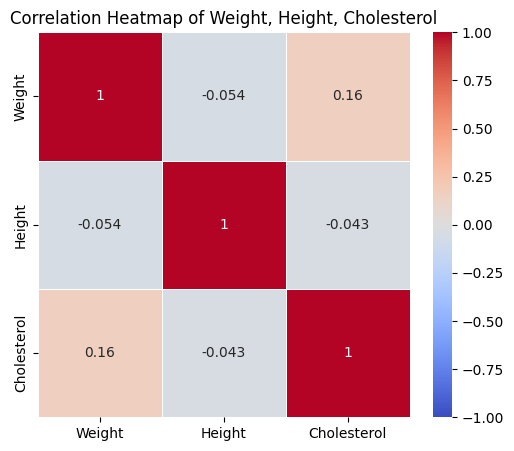

In [39]:
corr_matrix = df[cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title('Correlation Heatmap of Weight, Height, Cholesterol')
plt.show()

**Gender-Based Analysis**

In [40]:
for gender_value, label in zip([0,1], ['Female','Male']):
    subset = train_df[train_df['Gender']==gender_value]
    print(f"\n===== {label} Group Statistics =====")
    for col in ['Weight', 'Height']:
        data = subset[col]
        print(f"{col}: mean={data.mean():.2f}, var={data.var(ddof=1):.2f}, skew={stats.skew(data):.2f}")



===== Female Group Statistics =====
Weight: mean=75.59, var=212.45, skew=0.18
Height: mean=168.83, var=101.52, skew=-0.02

===== Male Group Statistics =====
Weight: mean=74.88, var=216.89, skew=0.14
Height: mean=168.78, var=97.32, skew=-0.00


In [41]:
from scipy.stats import norm, skew, kurtosis
for val in df['Gender'].unique():
    print(f"Gender value: {val}")
    print(df[df['Gender']==val].head())

Gender value: 1
   Gender      Height     Weight  Cholesterol  Diabetes
0       1  161.220174  67.928450   206.674781         0
2       1  167.735211  69.237118   177.087169         0
3       1  173.673655  52.588865   250.254190         0
4       1  179.135846  70.906916   145.829378         0
6       1  184.926886  69.649403   172.761944         0
Gender value: 0
    Gender      Height     Weight  Cholesterol  Diabetes
1        0  161.731196  77.664126   183.204176         0
5        0  161.968210  82.586370   212.018514         0
9        0  162.527883  69.684870   165.896972         0
14       0  170.669907  83.052525   160.406785         0
16       0  154.374541  73.277421   254.690489         0


In [42]:
def pmf_normal(data, bins):
    counts, edges = np.histogram(data, bins=bins)
    probs = counts / counts.sum()
    centers = 0.5 * (edges[1:] + edges[:-1])
    width = edges[1] - edges[0]
    return centers, probs, width, edges

In [43]:
def plot_row_pmf(df_subset, bins=10, suptitle=""):
    """Row of PMFs for Weight, Height and Cholesterol (relative-frequency)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, col in enumerate(cols):
        data = df_subset[col].values
        centers, probs, width, _ = pmf_normal(data, bins)
        ax = axes[i]
        ax.bar(centers, probs, width=width, color='skyblue', edgecolor='black', alpha=0.8)
        ax.set_title(f'PMF of {col} ({bins} bins)')
        ax.set_xlabel(col); ax.set_ylabel('Probability')
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        # sanity print
        print(f"{suptitle} {col} – sum(prob) = {probs.sum():.4f}")
    fig.suptitle(suptitle + " – PMFs", y=1.02, fontsize=13)
    plt.tight_layout(); plt.show()


In [44]:
def plot_row_cdf(df_subset, suptitle=""):
    """Row of CDF for Weight, Height and Cholesterol."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, col in enumerate(cols):
        x = np.sort(df_subset[col].values)
        n = len(x)
        y = np.arange(1, n+1) / n
        ax = axes[i]
        ax.plot(x, y, linewidth=1.8)
        ax.set_title(f'CDF of {col}')
        ax.set_xlabel(col); ax.set_ylabel('Cumulative Probability')
        ax.grid(True, linestyle='--', alpha=0.7)
    fig.suptitle(suptitle + " – CDFs", y=1.02, fontsize=13)
    plt.tight_layout(); plt.show()


In [45]:
bin_sets = [8, 20, 50]
def plot_grid_binwidths(df_subset, suptitle=""):
    """3x3 grid: rows = C/W/H, cols = bins 8/20/50 (PMF)."""
    fig, axes = plt.subplots(3, 3, figsize=(16, 12))
    for i, col in enumerate(cols):
        data = df_subset[col].values
        for j, b in enumerate(bin_sets):
            centers, probs, width, _ = pmf_normal(data, b)
            ax = axes[i, j]
            ax.bar(centers, probs, width=width, color='orange', edgecolor='black', alpha=0.75)
            ax.set_title(f'{col} – {b} bins', fontsize=11)
            ax.set_xlabel(col); ax.set_ylabel('Probability')
            ax.grid(axis='y', linestyle='--', alpha=0.7)
    fig.suptitle(suptitle + " – Bin-width comparison (PMF)", y=1.02, fontsize=13)
    plt.tight_layout(); plt.show()


In [46]:
def print_descriptive(df_subset, title=""):
    """Mean, variance, skewness, kurtosis."""
    print(f"\n{title} – Descriptive Statistics")
    print("-"*60)
    for col in cols:
        s = df_subset[col].values
        stats_dict = {
            'Mean'     : np.mean(s),
            'Variance' : np.var(s, ddof=1),
            'Skewness' : skew(s, bias=False),
            'Kurtosis' : kurtosis(s, fisher=True, bias=False)  # excess kurtosis
        }
        print(f"{col}: " + ", ".join([f"{k}={v:.4f}" for k,v in stats_dict.items()]))
    print("-"*60)


In [47]:
def plot_row_gaussian_overlays(df_subset, bins=50, suptitle=""):
    """Row of density histograms with Gaussian overlays."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for i, col in enumerate(cols):
        data = df_subset[col].values
        mu, sigma = data.mean(), data.std(ddof=1)
        x = np.linspace(data.min(), data.max(), 400)
        y = norm.pdf(x, mu, sigma)

        ax = axes[i]
        ax.hist(data, bins=bins, density=True, alpha=0.6, color='skyblue', edgecolor='black')
        ax.plot(x, y, color='red', linewidth=2, label=f'N({mu:.2f}, {sigma:.2f})')
        ax.set_title(f'Gaussian Overlay – {col}')
        ax.set_xlabel(col); ax.set_ylabel('Density')
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend()
    fig.suptitle(suptitle + " – Gaussian fits", y=1.02, fontsize=13)
    plt.tight_layout(); plt.show()


In [48]:
def correlation_and_cov(df_subset, title=""):
    """Print Covariance & Correlation for (W,H), (W,C), (H,C) and a correlation heatmap """
    pairs = [('Weight', 'Height'), ('Weight', 'Cholesterol'), ('Height', 'Cholesterol')]
    print(f"\n{title} – ")
    print("-"*60)
    for a,b in pairs:
        cov = np.cov(df_subset[a].values, df_subset[b].values, ddof=1)[0,1]
        corr = np.corrcoef(df_subset[a].values, df_subset[b].values)[0,1]
        print(f"({a}, {b}): Cov={cov:.4f}, Corr={corr:.4f}")
    print("-"*60)

    # correlation heatmap
    corr_m = df_subset[cols].corr().values
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    cax = ax.imshow(corr_m, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols)
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels(cols)
    ax.set_title(title + " – Correlation matrix")
    for (r, c), v in np.ndenumerate(corr_m):
      ax.text(c, r, f"{v:.2f}", ha='center', va='center',
            color='white' if abs(v) > 0.6 else 'black')
    fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

In [49]:
def comment_correlations(df_subset, title=""):
    pairs = [('Weight', 'Height'), ('Weight', 'Cholesterol'), ('Height', 'Cholesterol')]
    print(f"\n{title} – Correlation comments")
    for a,b in pairs:
        r = df_subset[[a,b]].corr().iloc[0,1]
        if abs(r) < 0.2:
            level = "very weak / none"
        elif abs(r) < 0.5:
            level = "weak"
        elif abs(r) < 0.8:
            level = "moderate"
        else:
            level = "strong"
        print(f"{a} vs {b}: r={r:.3f} → {level}")

In [50]:
def analyze_gender(df_subset, label):
    # 1) PMFs (10 bins)
    plot_row_pmf(df_subset, bins=10, suptitle=f"{label}")
    # 2) CDFs
    plot_row_cdf(df_subset, suptitle=f"{label}")
    # 3) Bin-width comparison grid (8,20,50)
    plot_grid_binwidths(df_subset, suptitle=f"{label}")
    # 4) Descriptive stats
    print_descriptive(df_subset, title=f"{label}")
    # 5) Gaussian overlays
    plot_row_gaussian_overlays(df_subset, bins=20, suptitle=f"{label}")
    # 6) Covariance & correlation + matrix
    correlation_and_cov(df_subset, title=f"{label}")
    # 7) Narrative comments
    comment_correlations(df_subset, title=f"{label}")

Female Class Weight – sum(prob) = 1.0000
Female Class Height – sum(prob) = 1.0000
Female Class Cholesterol – sum(prob) = 1.0000


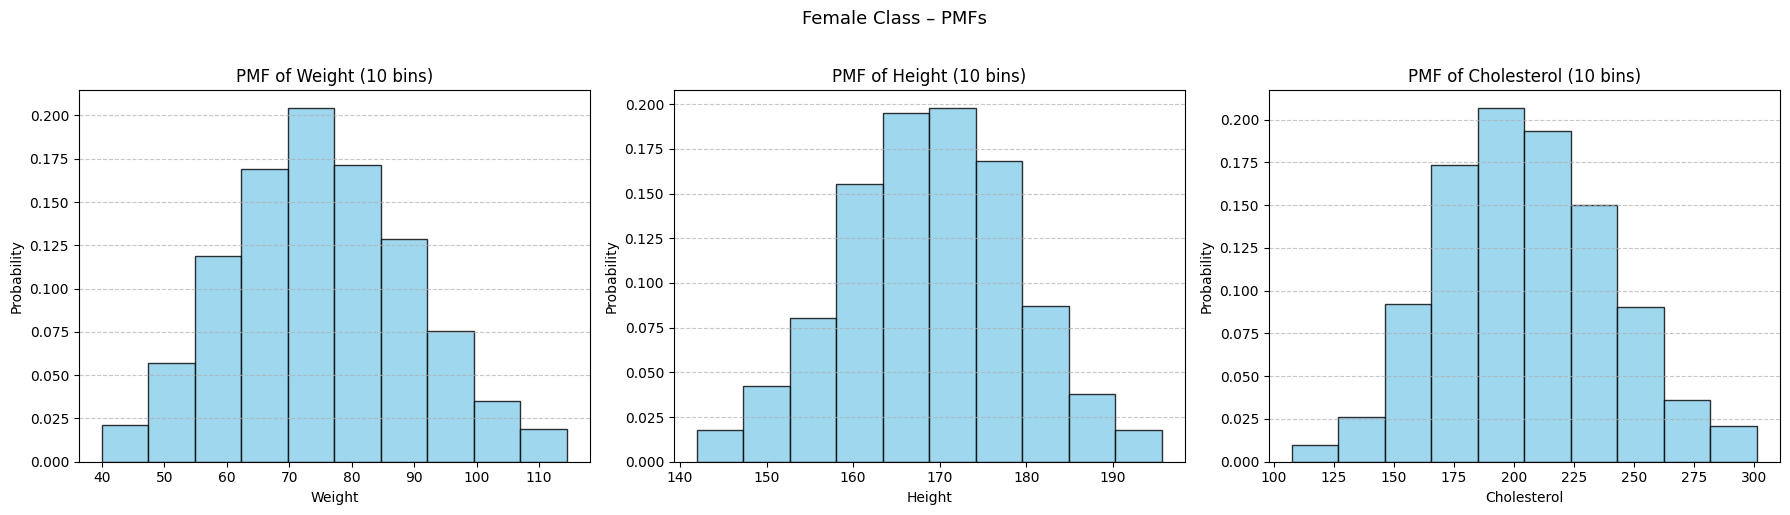

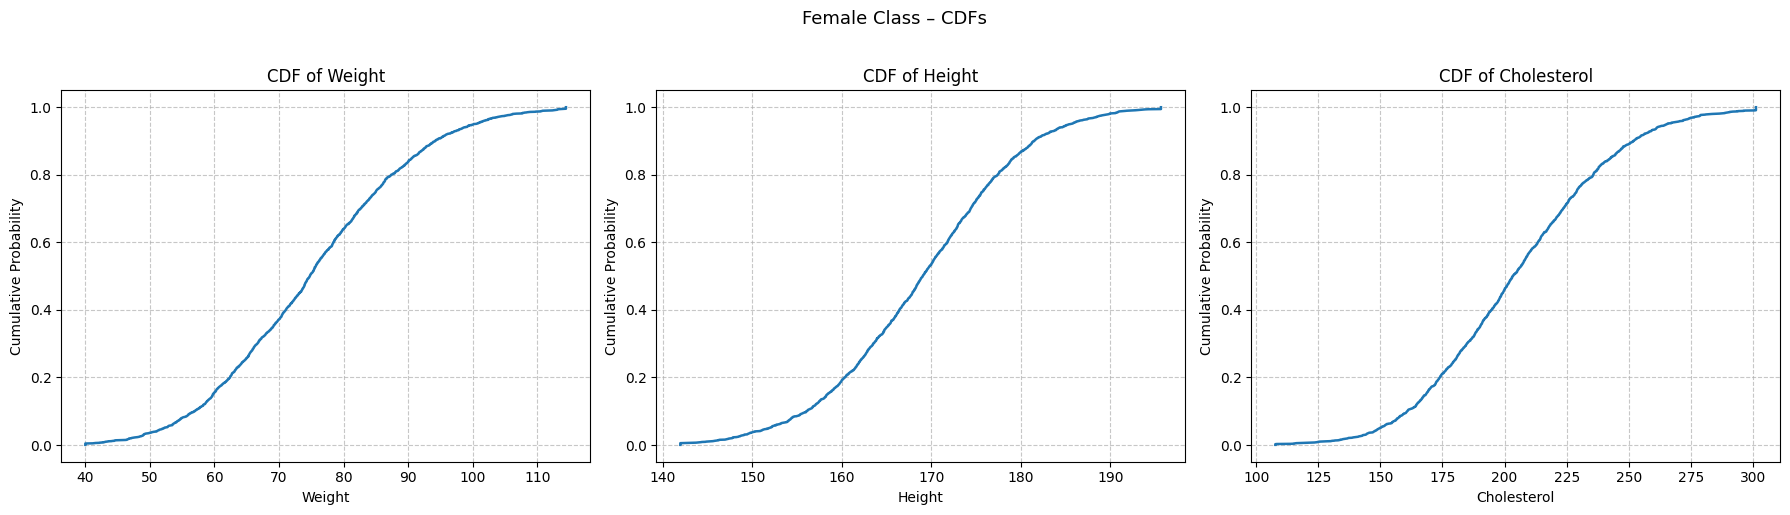

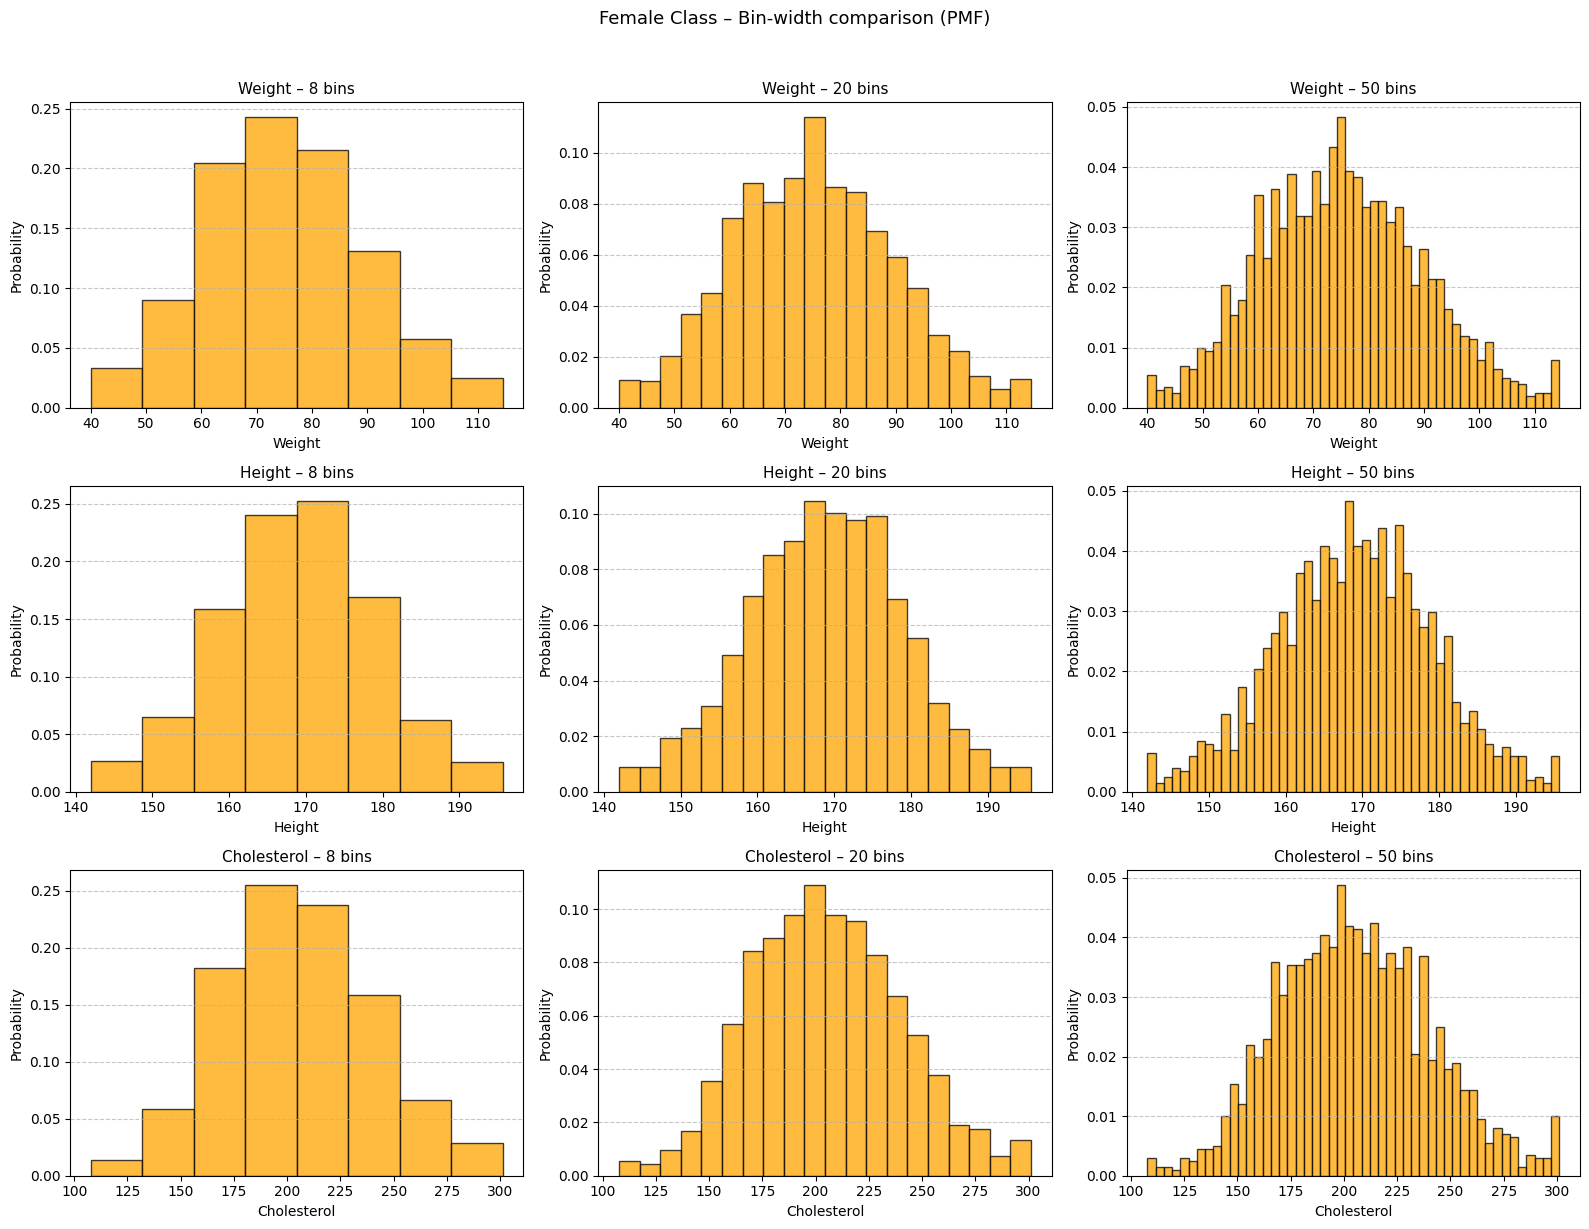


Female Class – Descriptive Statistics
------------------------------------------------------------
Weight: Mean=75.1779, Variance=211.7293, Skewness=0.1787, Kurtosis=-0.2555
Height: Mean=168.9252, Variance=101.7516, Skewness=-0.0449, Kurtosis=-0.1303
Cholesterol: Mean=205.2263, Variance=1264.9942, Skewness=0.1925, Kurtosis=-0.1241
------------------------------------------------------------


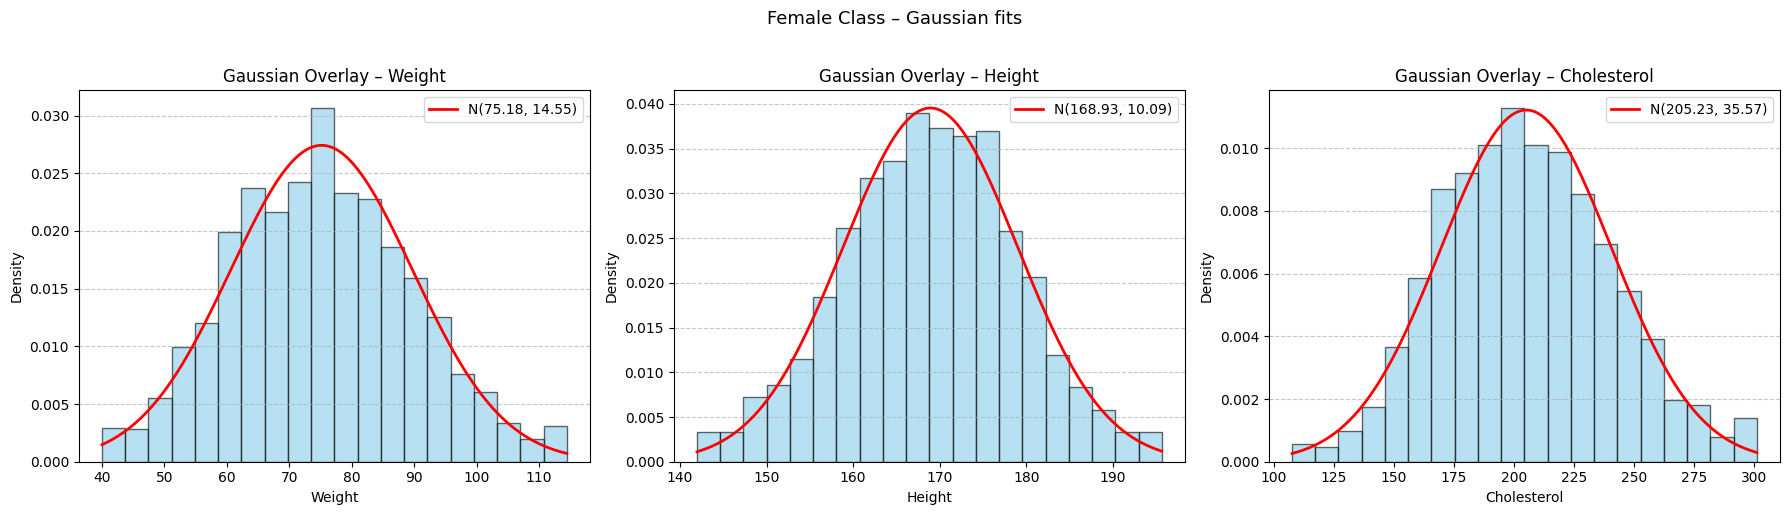


Female Class – 
------------------------------------------------------------
(Weight, Height): Cov=-9.3514, Corr=-0.0637
(Weight, Cholesterol): Cov=88.6616, Corr=0.1713
(Height, Cholesterol): Cov=-21.5740, Corr=-0.0601
------------------------------------------------------------

Female Class – Correlation comments
Weight vs Height: r=-0.064 → very weak / none
Weight vs Cholesterol: r=0.171 → very weak / none
Height vs Cholesterol: r=-0.060 → very weak / none


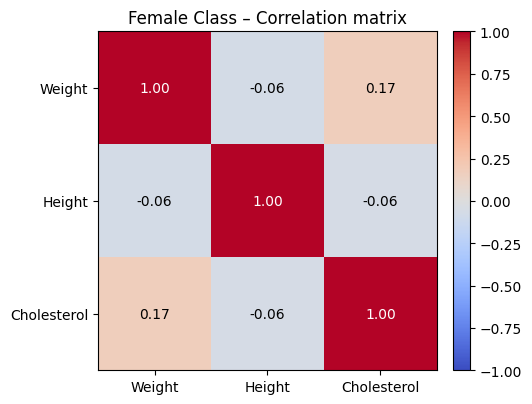

In [51]:
cols = ['Weight', 'Height', 'Cholesterol']

# Assuming LabelEncoder default: 0 = Female, 1 = Male
df_female = df[df['Gender'] == 0] # Changed 'F' to 0
df_male   = df[df['Gender'] == 1] # Changed 'M' to 1

analyze_gender(df_female, "Female Class")

Male Class  Weight – sum(prob) = 1.0000
Male Class  Height – sum(prob) = 1.0000
Male Class  Cholesterol – sum(prob) = 1.0000


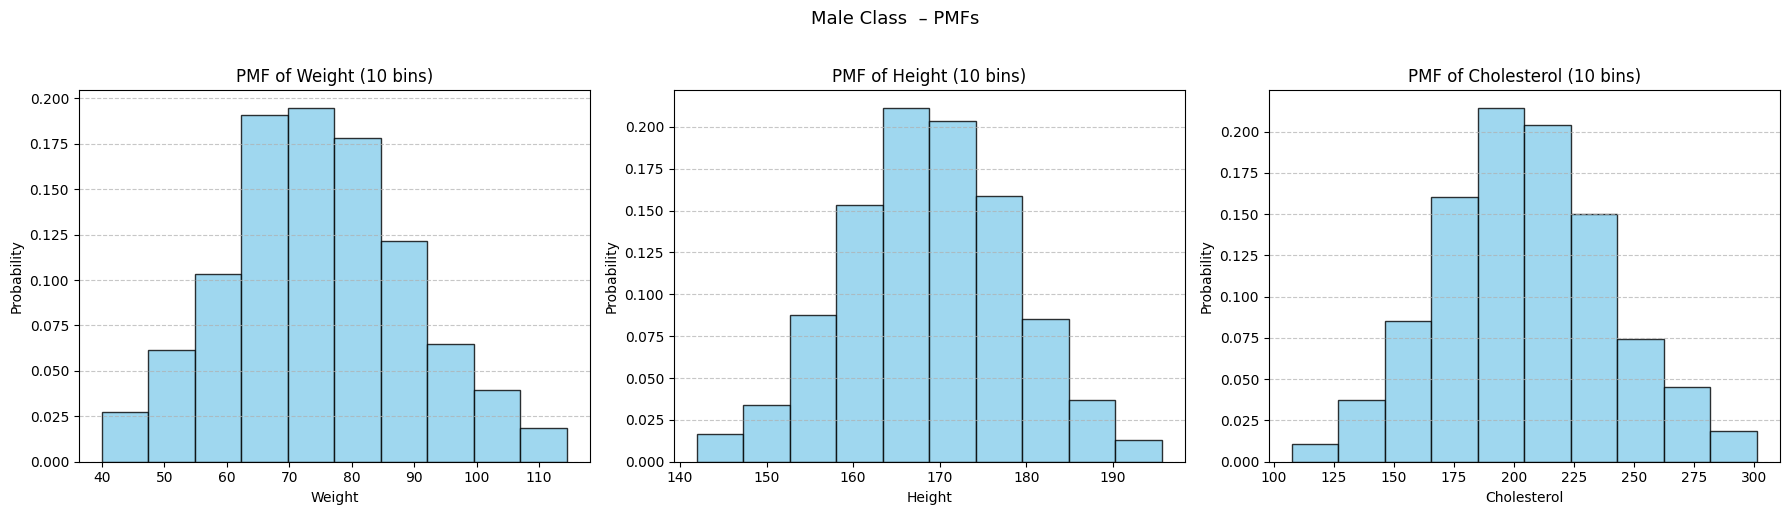

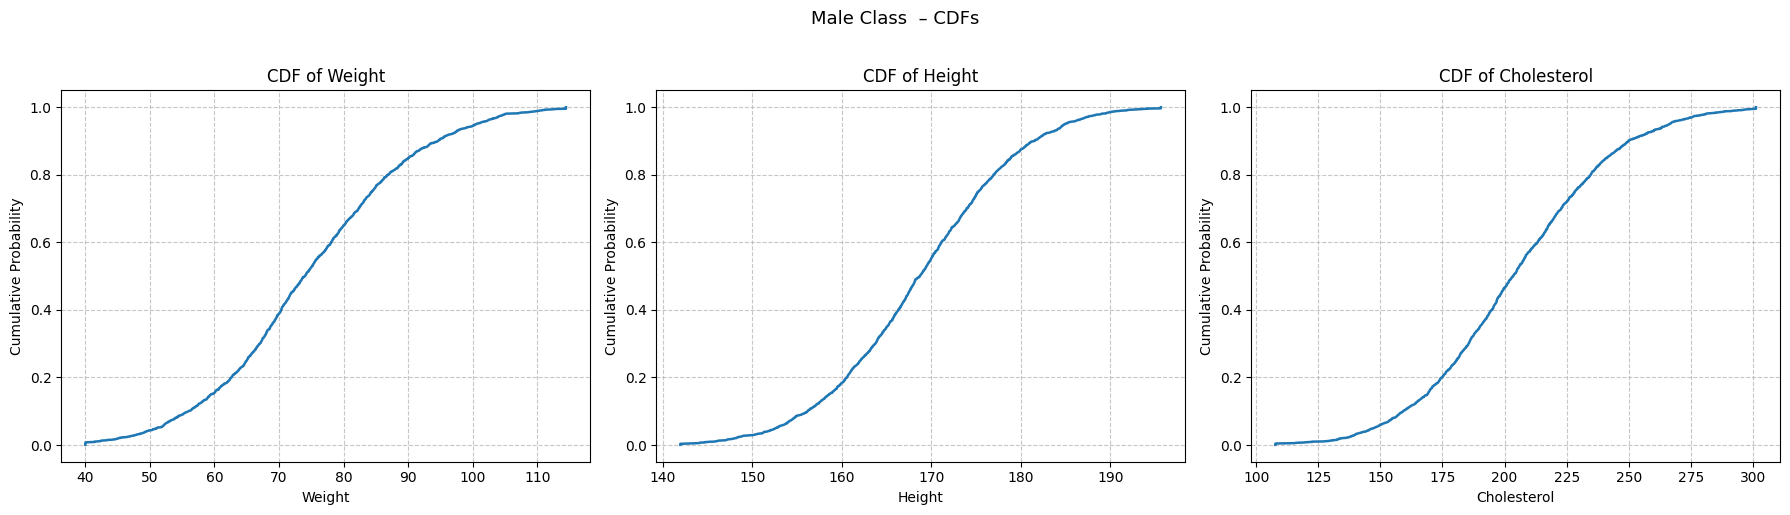

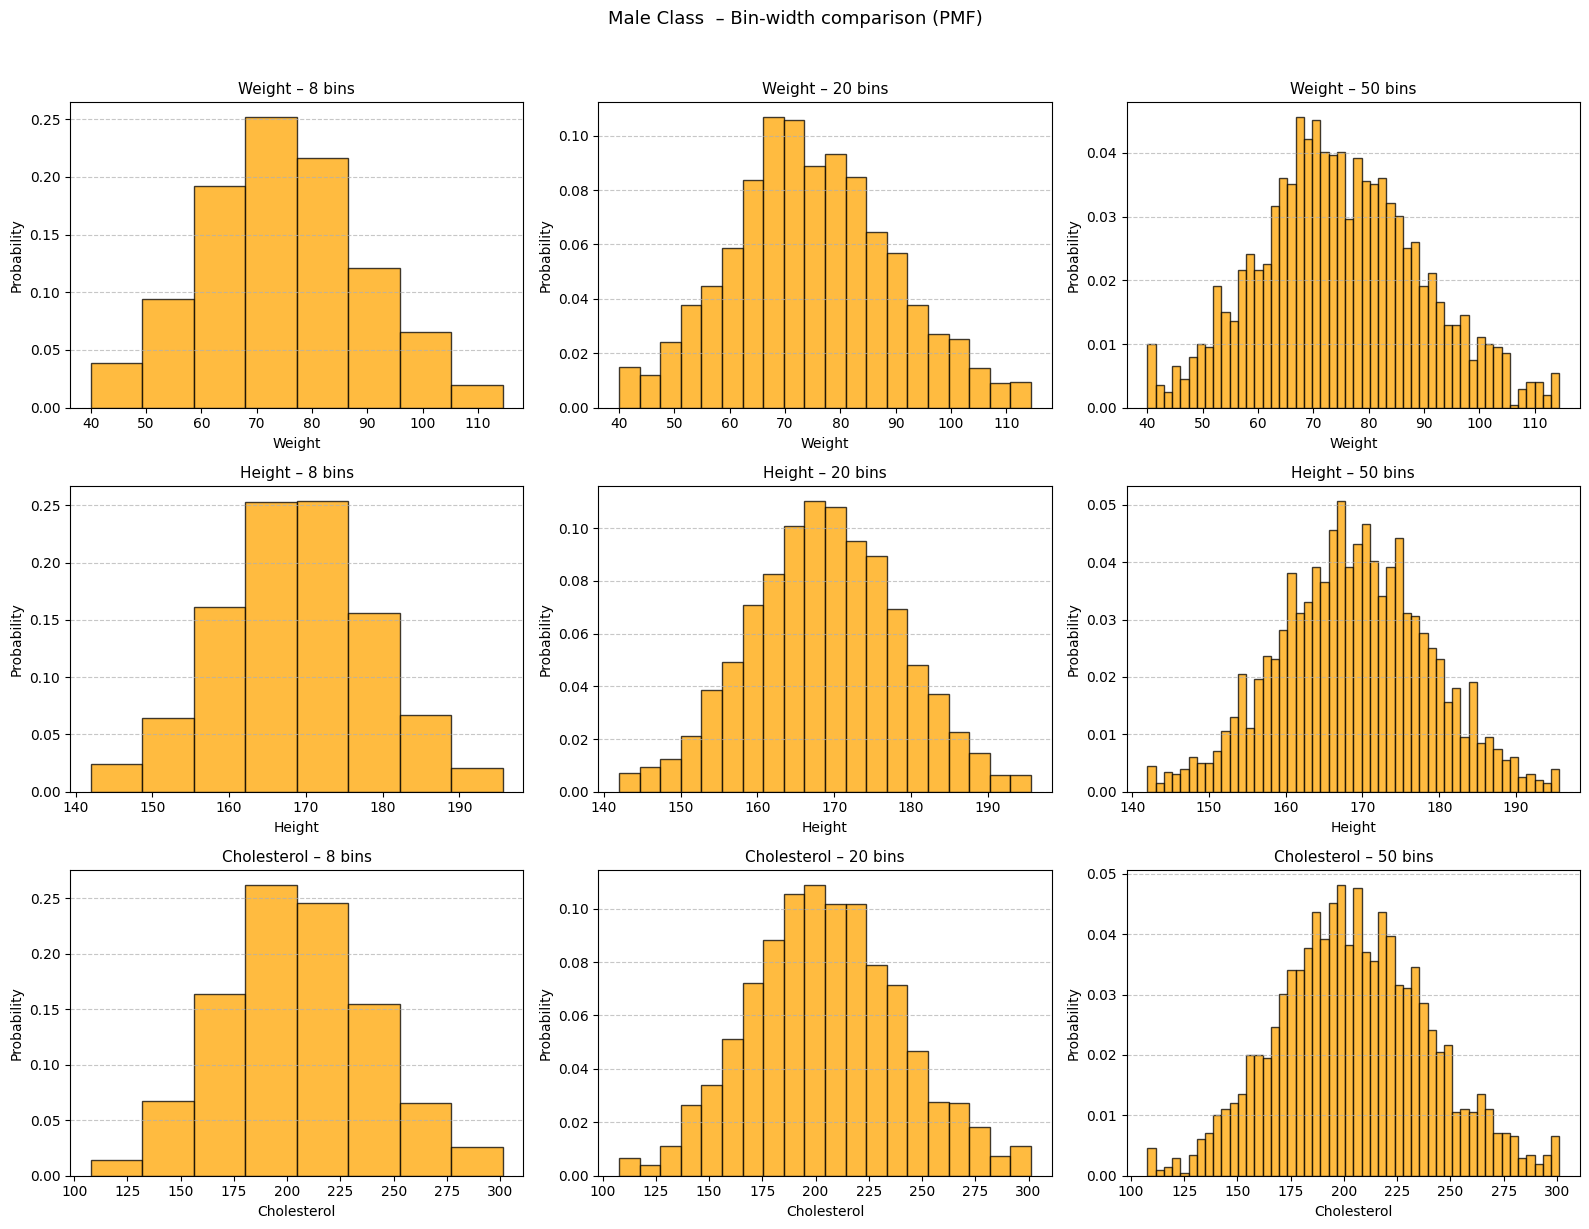


Male Class  – Descriptive Statistics
------------------------------------------------------------
Weight: Mean=74.7513, Variance=215.5959, Skewness=0.1549, Kurtosis=-0.1976
Height: Mean=168.7605, Variance=96.1541, Skewness=-0.0039, Kurtosis=-0.1330
Cholesterol: Mean=204.6663, Variance=1266.1156, Skewness=0.1250, Kurtosis=-0.0994
------------------------------------------------------------


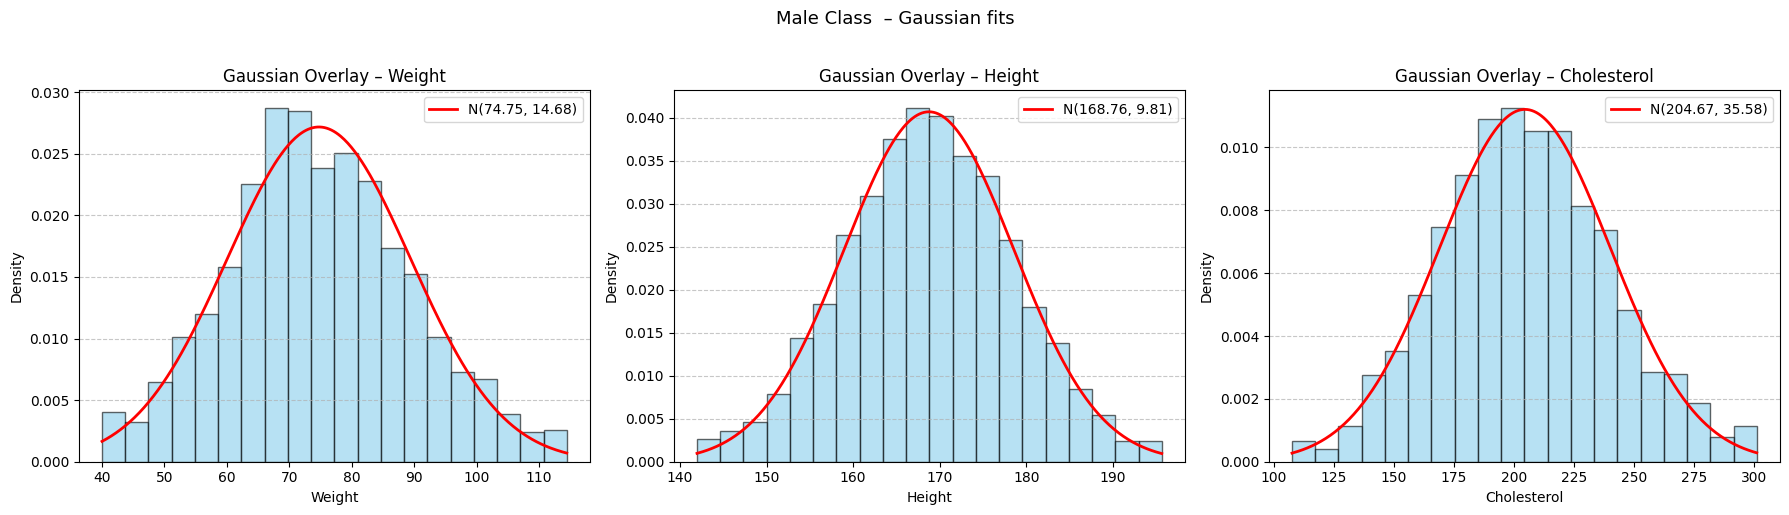


Male Class  – 
------------------------------------------------------------
(Weight, Height): Cov=-6.4613, Corr=-0.0449
(Weight, Cholesterol): Cov=80.0372, Corr=0.1532
(Height, Cholesterol): Cov=-8.6657, Corr=-0.0248
------------------------------------------------------------

Male Class  – Correlation comments
Weight vs Height: r=-0.045 → very weak / none
Weight vs Cholesterol: r=0.153 → very weak / none
Height vs Cholesterol: r=-0.025 → very weak / none


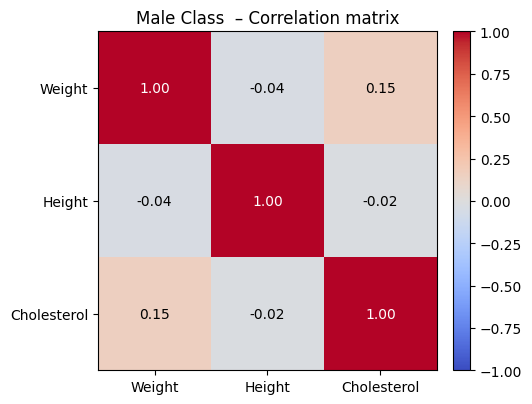

In [52]:
analyze_gender(df_male, "Male Class ")

**Linear Regression (Predicting Weight from Height and Predicting Diabetes from Cholesterol )**


Correlation between actual and predicted Weight: 0.062
Regression equation: Weight = -0.09 * Height + 90.71


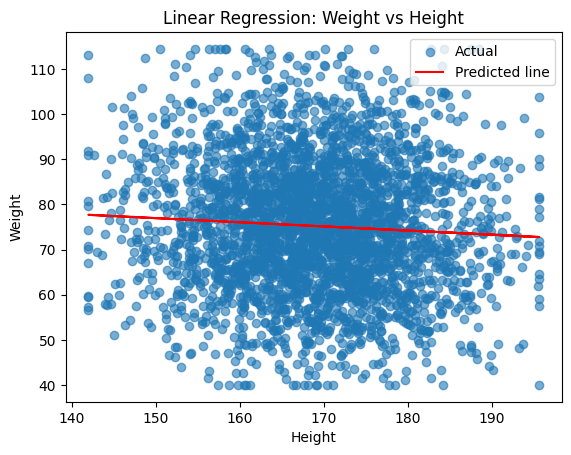

Correlation coefficient between Diabetes and Cholesterol: 0.4429309014824414


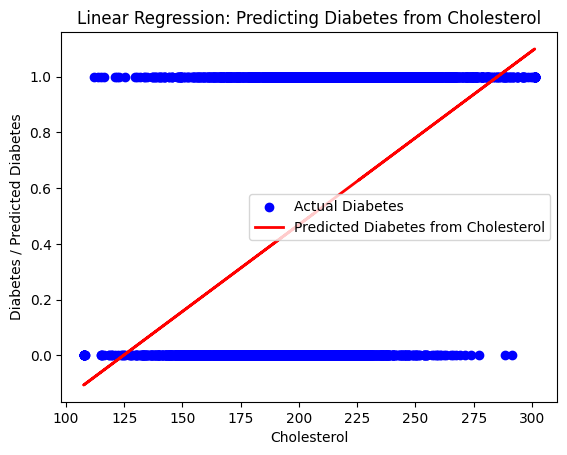

In [55]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# Predict W from H

X = train_df[['Height']]
y = train_df['Weight']

lr = LinearRegression()
lr.fit(X, y)
train_df['Weight_pred'] = lr.predict(X)

r_weight = np.corrcoef(train_df['Weight'], train_df['Weight_pred'])[0,1]
print(f"\nCorrelation between actual and predicted Weight: {r_weight:.3f}")
print("Regression equation: Weight = %.2f * Height + %.2f" % (lr.coef_[0], lr.intercept_))

plt.scatter(train_df['Height'], train_df['Weight'], label='Actual', alpha=0.6)
plt.plot(train_df['Height'], train_df['Weight_pred'], color='red', label='Predicted line')
plt.title('Linear Regression: Weight vs Height')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.legend()
plt.show()

# Predict D from C

X = df[['Cholesterol']].values.reshape(-1, 1)
y = df['Diabetes'].values


model_DfC = LinearRegression()
model_DfC.fit(X, y)


DfC = model_DfC.predict(X)


corr_D_DfC = np.corrcoef(y, DfC)[0, 1]

print("Correlation coefficient between Diabetes and Cholesterol:", corr_D_DfC)


plt.scatter(X, y, color='blue', label='Actual Diabetes')
plt.plot(X, DfC, color='red', label='Predicted Diabetes from Cholesterol', linewidth=2)
plt.xlabel('Cholesterol')
plt.ylabel('Diabetes / Predicted Diabetes')
plt.title('Linear Regression: Predicting Diabetes from Cholesterol')
plt.legend()
plt.show()

**Logistic Regression (Predicting Diabetes)**


Classification Report (Logistic Regression):

              precision    recall  f1-score   support

           0       0.65      0.70      0.68       400
           1       0.68      0.62      0.65       400

    accuracy                           0.66       800
   macro avg       0.66      0.66      0.66       800
weighted avg       0.66      0.66      0.66       800

Confusion Matrix:
 [[282 118]
 [153 247]]
Accuracy: 0.66125
AUC: 0.722175


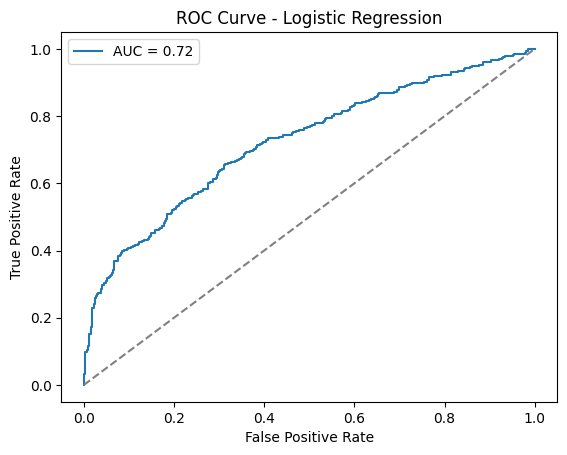

In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

features = ['Weight','Height','Gender']
X_train = train_df[features].copy()
y_train = train_df['Diabetes']
X_test = test_df[features].copy()
y_test = test_df['Diabetes']

# Encode 'Gender' column
le = LabelEncoder()
X_train['Gender'] = le.fit_transform(X_train['Gender'])
X_test['Gender'] = le.transform(X_test['Gender'])

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:,1]

print("\nClassification Report (Logistic Regression):\n")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_prob))

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.2f}")
plt.plot([0,1],[0,1],'--', color='gray')
plt.title('ROC Curve - Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

**Naive Bayes**

Naïve Bayes Model Accuracy: 0.6625


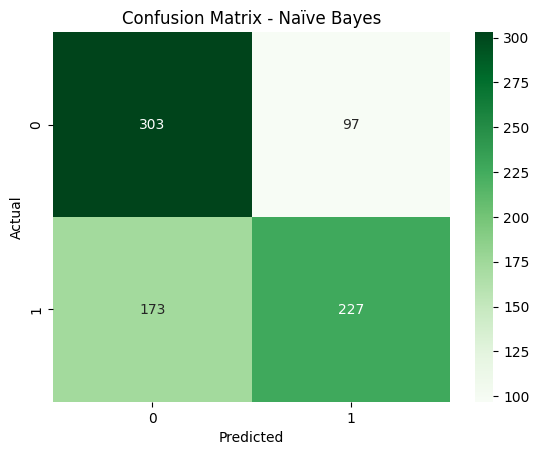


Classification Report - Naïve Bayes:
              precision    recall  f1-score   support

           0       0.64      0.76      0.69       400
           1       0.70      0.57      0.63       400

    accuracy                           0.66       800
   macro avg       0.67      0.66      0.66       800
weighted avg       0.67      0.66      0.66       800



In [58]:

naive_bayes = GaussianNB()
naive_bayes.fit(X_train_scaled, y_train)


y_pred_nb = naive_bayes.predict(X_test_scaled)

acc_nb = accuracy_score(y_test, y_pred_nb)
print(f"Naïve Bayes Model Accuracy: {acc_nb:.4f}")

cm_nb = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - Naïve Bayes')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print("\nClassification Report - Naïve Bayes:")
print(classification_report(y_test, y_pred_nb))

**Decision Tree Classifier**

In [60]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)
print("\nDecision Tree Report:\n")
print(classification_report(y_test, y_pred_tree))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_tree))
print("Accuracy:", accuracy_score(y_test, y_pred_tree))


Decision Tree Report:

              precision    recall  f1-score   support

           0       0.66      0.69      0.68       400
           1       0.68      0.65      0.66       400

    accuracy                           0.67       800
   macro avg       0.67      0.67      0.67       800
weighted avg       0.67      0.67      0.67       800

Confusion Matrix:
 [[275 125]
 [139 261]]
Accuracy: 0.67


In [61]:
print("\nSUMMARY OF RESULTS ")
print(f"Mean Weight: {train_df['Weight'].mean():.2f}")
print(f"Mean Height: {train_df['Height'].mean():.2f}")
print(f"Weight~Height Correlation: {r_weight:.3f}")
print("Logistic Regression AUC:", round(roc_auc_score(y_test, y_prob),3))
print("Decision Tree Accuracy:", round(accuracy_score(y_test, y_pred_tree),3))


SUMMARY OF RESULTS 
Mean Weight: 75.23
Mean Height: 168.80
Weight~Height Correlation: 0.062
Logistic Regression AUC: 0.722
Decision Tree Accuracy: 0.67
